# Paso 16 · Algoritmos de QFT: cómo funcionan por dentro (con Python)

Notebook del **Paso 16**: la tubería de seis algoritmos (templates → especificaciones → bounds → loop shaping → prefiltro → verificación), con las trampas típicas y la comparación *rejilla* frente a *exacto*.

| Algoritmo | Qué se programa |
|---|---|
| 1. templates | `template`, borde de la caja, **trampa de la envolvente convexa** |
| 2. bounds por rejilla | `allowed_map` (máscara fase × dB × plantas) |
| 2b. bounds exactos | desigualdades cuadráticas $ax^2+bx+c\ge0$ |
| 3. loop shaping automático | `differential_evolution` + bucle de refinado |
| 4–5. prefiltro y verificación | búsqueda del polo de $F$, barrido denso |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

AZUL, NARANJA, TINTA, GRIS = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e3e2de", "axes.axisbelow": True,
                     "font.size": 10})
np.set_printoptions(precision=4, suppress=True)

In [2]:
import time
from nbhelp import db, wrapfase, AZUL, NARANJA, TINTA, GRIS, VERDE
import qftlib as q                                  # code/python/qftlib.py (nbhelp añade la ruta)

P = lambda w, K, a: K / (1j*w*(1j*w + a))
thetas = q.plant_family([np.linspace(1, 5, 17), np.linspace(1, 3, 13)])           # 221 plantas (K, a)
Ws = 1.2
TU = lambda w: abs(1/((1j*w/8)**2 + 2*0.6*(1j*w/8) + 1)); TL = lambda w: abs(1/(1j*w/1.2 + 1)**3)
delta_db = lambda w: 20*np.log10(TU(w)/TL(w)); Wd = lambda w: 0.3 if w <= 0.5 else (0.5 if w <= 1.0 else 10.0)
specs = [q.spec_stability(Ws), q.spec_tracking(delta_db), q.spec_disturbance(Wd)]
idx = q.boundary_indices(thetas); G9 = lambda s: 5*(1 + s/2)/(1 + s/20)
P0 = lambda w: P(w, 1.0, 1.0)
print(f"{len(thetas)} plantas; borde de la caja: {len(idx)} plantas")

221 plantas; borde de la caja: 56 plantas


## 1. La tubería en seis algoritmos

`familia → templates → bounds → loop shaping → prefiltro → verificación`. Cada paso del curso anterior es un algoritmo; aquí vemos qué cuesta cada elección y qué errores son típicos.

## 2. Algoritmo 1: templates y el borde de la caja

El template completo son 221 puntos; para calcular bounds basta el **borde de la caja de parámetros** (56 plantas). Pero la **envolvente convexa** del template (15 puntos) parece más barata y **da un resultado incorrecto**:

celdas que el método da por PERMITIDAS y no lo son:  borde (56): 0   envolvente (15): 263


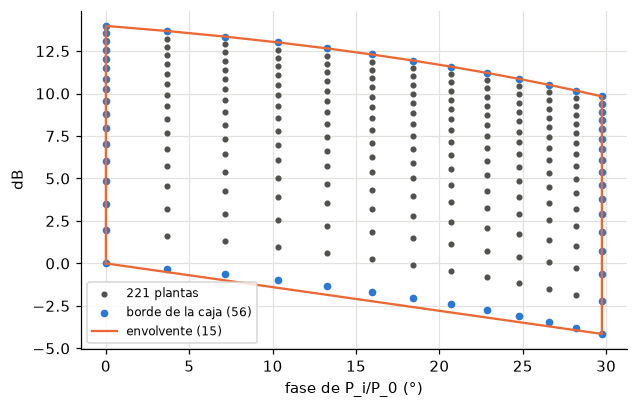

In [3]:
w = 2.0
z = q.template(P, thetas, w); r = z / P0(w)
hull = q.hull_indices(r)
full = q.allowed_map(w, r, specs)                        # referencia: las 221 plantas
borde = q.allowed_map(w, r, specs, idx=idx)
casc = q.allowed_map(w, r, specs, idx=hull)
print(f"celdas que el método da por PERMITIDAS y no lo son:  borde ({len(idx)}): {int((borde & ~full).sum())}   envolvente ({len(hull)}): {int((casc & ~full).sum())}")

fig, ax = plt.subplots(figsize=(6.4, 4))
ph, gd = np.degrees(np.angle(r)), db(r)
ax.scatter(ph, gd, s=9, color=GRIS, label="221 plantas"); ax.scatter(ph[idx], gd[idx], s=16, color=AZUL, label="borde de la caja (56)")
hv = hull[np.argsort(np.arctan2(gd[hull] - gd[hull].mean(), ph[hull] - ph[hull].mean()))]
ax.plot(np.r_[ph[hv], ph[hv][0]], np.r_[gd[hv], gd[hv][0]], color=NARANJA, label=f"envolvente ({len(hull)})")
ax.set_xlabel("fase de P_i/P_0 (°)"); ax.set_ylabel("dB"); ax.legend(fontsize=8); plt.show()

Por qué: la **dispersión** de $|T_i|$ es máximo menos mínimo, y las plantas que dan el máximo o el mínimo pueden estar *dentro* del contorno del template, no en su envolvente.

### Qué cuesta cada elección

In [4]:
def tiempo(sel, rep=2):
    t = 1e9
    for _ in range(rep):
        t0 = time.time(); q.allowed_map(w, r, specs, idx=sel); t = min(t, time.time() - t0)
    return 1e3*t
print(f"{'plantas':<34}{'n':>5}{'errores':>9}{'tiempo':>10}")
for nombre, sel in (("todas", None), ("borde de la caja", idx), ("envolvente convexa", hull)):
    m = q.allowed_map(w, r, specs, idx=sel); n = len(r) if sel is None else len(sel)
    print(f"{nombre:<34}{n:>5}{int((m & ~full).sum()):>9}{tiempo(sel):>8.0f} ms")

plantas                               n  errores    tiempo


todas                               221        0    1709 ms


borde de la caja                     56        0     442 ms


envolvente convexa                   15      263     105 ms


## 3. Algoritmo 2: el mapa de bounds por rejilla

Para cada celda (fase, módulo) se construye $L_0$, se multiplica por el vector de cocientes $r_i$ (*broadcasting*: forma `[n_fase, n_módulo, n_plantas]`) y se aplican las especificaciones. **Memoria**: $360\times241\times56$ complejos ≈ 78 MB.

In [5]:
print("L0 de la rejilla:", (len(q.PH), len(q.MG)), "-> con", len(idx), "plantas:", (len(q.PH), len(q.MG), len(idx)), f"= {len(q.PH)*len(q.MG)*len(idx)*16/1e6:.0f} MB (complex128)")
m1 = q.allowed_map(1.0, q.template(P, thetas, 1.0)/P0(1.0), specs, idx=idx)
print("celdas permitidas / prohibidas en ω = 1:", int(m1.sum()), "/", int((~m1).sum()))
L = G9(1j*1.0)*P0(1.0)
print(f"margen de L0(j1) frente al mapa: {q.margin_db(m1, float(q.wrap_phase(L)), db(L)):.2f} dB")

L0 de la rejilla: (360, 241) -> con 56 plantas: (360, 241, 56) = 78 MB (complex128)


celdas permitidas / prohibidas en ω = 1: 33880 / 52880
margen de L0(j1) frente al mapa: 0.93 dB


## 4. Una fórmula cerrada para el bound de estabilidad (y un *test*)

Con $u=r_ie^{j\varphi}$ y $L=x\,u$, $|T|\le W_s$ ⟺ $A x^2+2W_s^2\mathrm{Re}(u)\,x+W_s^2\ge0$ con $A=(W_s^2-1)|u|^2$. Se incumple entre las dos raíces:
$$x_\pm=\frac{-W_s^2\mathrm{Re}(u)\pm\sqrt{W_s^2\,(W_s^2\mathrm{Re}(u)^2-(W_s^2-1)|u|^2)}}{A}.$$
La unión de intervalos sobre las plantas es el bound. Lo usamos para **comprobar** el código de rejilla (0 celdas distintas):

In [6]:
def intervalos(w, fase_deg):
    out = []
    for ri in (q.template(P, thetas, w)/P0(w))[idx]:
        u = ri*np.exp(1j*np.radians(fase_deg)); A = (Ws**2 - 1)*abs(u)**2
        D = Ws**2*(Ws**2*u.real**2 - (Ws**2 - 1)*abs(u)**2)
        if D > 0 and u.real < 0:
            x1 = (-Ws**2*u.real - np.sqrt(D))/A; x2 = (-Ws**2*u.real + np.sqrt(D))/A
            if x2 > 0: out.append((20*np.log10(max(x1, 1e-9)), 20*np.log10(x2)))
    return out

for wv in (1.0, 2.0):
    m = q.allowed_map(wv, q.template(P, thetas, wv)/P0(wv), [q.spec_stability(Ws)], idx=idx)
    dif = sum((any(a <= g <= b for a, b in intervalos(wv, ph)) == m[i, j]) for i, ph in enumerate(q.PH) for j, g in enumerate(q.MG))
    print(f"ω = {wv}: fórmula cerrada frente a la rejilla ({m.size} celdas): celdas distintas = {dif}")

ω = 1.0: fórmula cerrada frente a la rejilla (86760 celdas): celdas distintas = 0


ω = 2.0: fórmula cerrada frente a la rejilla (86760 celdas): celdas distintas = 0


## 5. Bounds exactos: una desigualdad cuadrática por especificación

Estabilidad, perturbación y seguimiento (por **pares** de plantas, $|T_d|/|T_e|\le R$) se reducen a $a x^2+bx+c\ge0$ con $x=|L_0|$. Resultado: el bound **exacto**, sin rejilla de módulo, y el margen real de $L_0$:

In [7]:
G9 = lambda s: 5*(1 + s/2)/(1 + s/20)
print(f"{'ω':>5} {'celdas distintas':>17} {'margen exacto':>15} {'margen por rejilla':>20}")
for wv in (0.5, 1.0, 2.0):
    rr = q.template(P, thetas, wv)/P0(wv); R = 10**(delta_db(wv)/20)
    quads = [q.quad_stability(Ws), q.quad_disturbance(Wd(wv)), q.quad_tracking_pairs(R)]
    m = q.allowed_map(wv, rr, specs, idx=idx); dif = 0
    for i, ph in enumerate(q.PH):
        forb = np.zeros(len(q.MG), bool)
        for lo, hi in q.exact_forbidden(rr[idx], ph, quads): forb |= (q.MG >= lo) & (q.MG <= hi)
        dif += int(np.sum(forb == m[i]))
    L = G9(1j*wv)*P0(wv)
    me = q.exact_margin_db(rr[idx], float(q.wrap_phase(L)), db(L), quads)
    mg = q.margin_db(m, float(q.wrap_phase(L)), db(L))
    print(f"{wv:>5} {dif:>17} {me:>12.3f} dB {mg:>17.2f} dB")

    ω  celdas distintas   margen exacto   margen por rejilla


  0.5                 0        0.701 dB              0.79 dB


  1.0                 0        0.627 dB              0.93 dB


  2.0                 0       17.673 dB             17.94 dB


El exacto coincide con la rejilla (0 celdas distintas) y da el margen real (la rejilla de 0.5 dB lo redondea). El mapa sirve para **dibujar** el bound; el exacto, para **decidir** si $L_0$ cumple.

## 6. Algoritmo 3: loop shaping automático y el bucle de refinado

Se busca $(k,z,p)$ con `differential_evolution` minimizando $G(\infty)=kp/z$ más $10^3\times$ los dB de violación. Como sólo se usa un número finito de frecuencias, se **verifica en denso** y se **añaden** las que fallan:

In [8]:
wlist = [0.1, 0.5, 1, 2, 5, 10, 20, 50]
wdense = np.logspace(-2, np.log10(60), 400)
Pfam = lambda w: q.template(P, thetas, w)
make_map = lambda w: q.allowed_map(w, Pfam(w)/P0(w), specs, idx=idx)

t0 = time.time()
x, hist = q.synthesize_refine(P0, Pfam, specs, wlist, wdense, make_map)
print(f"{'k':>7} {'z':>7} {'p':>7} {'G(inf)':>8} {'fallos':>7} {'n_w':>5}")
for xx, ginf, nbad, nw in hist: print(f"{xx[0]:7.3f} {xx[1]:7.3f} {xx[2]:7.3f} {ginf:8.2f} {nbad:7d} {nw:5d}")
print(f"\n{time.time() - t0:.1f} s en total.  Diseño final: G = {x[0]:.3f}(1 + s/{x[1]:.3f})/(1 + s/{x[2]:.2f});  G(∞) = {hist[-1][1]:.1f} (a mano: 50)")

      k       z       p   G(inf)  fallos   n_w
  5.002   2.216  13.095    29.55      33     8
  5.129   2.650  16.579    32.08      16    11
  5.084   2.467  16.070    33.12       6    14
  5.103   2.541  16.564    33.27       1    17
  5.099   2.537  16.533    33.23       1    18
  4.714   2.107  14.791    33.09       1    19
  4.714   2.107  14.791    33.09       1    20
  5.095   2.521  16.425    33.19       0    21

19.6 s en total.  Diseño final: G = 5.095(1 + s/2.521)/(1 + s/16.43);  G(∞) = 33.2 (a mano: 50)


## 7. Algoritmos 4 y 5: prefiltro y verificación densa

In [9]:
Tfam = lambda w: np.abs((lambda L: L/(1 + L))(G9(1j*w)*Pfam(w)))
m, f = q.prefilter_search(Tfam, TU, TL, np.logspace(-1, np.log10(40), 60), np.arange(0.5, 3.01, 0.1))
print(f"prefiltro F = 1/(1 + s/f) óptimo con el G del paso 9: f = {f:.1f}, margen mínimo en la banda = {m:.3f} dB")
bad = q.verify(lambda w: G9(1j*w)*Pfam(w), wdense, specs)
print("verificación densa del G del paso 9:", len(bad), "frecuencias que fallan")

prefiltro F = 1/(1 + s/f) óptimo con el G del paso 9: f = 1.1, margen mínimo en la banda = 0.028 dB
verificación densa del G del paso 9: 0 frecuencias que fallan


## 8. En discreto: qué cambia en el algoritmo

Sólo cambian dos cosas: la planta pasa de $P(j\omega)$ a $P(e^{j\omega T_s})$ (ZOH) y la lista de frecuencias acaba en Nyquist. Los mapas, bounds, DE y la verificación son idénticos.

## 9. Errores típicos al programar QFT

1. Fase en $[0,360)$ frente a $[-360,0)$: usar siempre `wrap_phase`.
2. Olvidar que $-359^\circ$ y $+1^\circ$ son la misma columna (`mod 360`).
3. Usar la envolvente convexa del template (sección 2).
4. Rejilla de módulo demasiado gruesa: el margen cambia ~1 dB.
5. Diseñar con 8 frecuencias y no verificar en denso.
6. Confundir $\omega$ con $\nu$ (plano $w$).

## 10. Ejercicio del Paso 16

1. ¿Cuántas evaluaciones de $T$ hace un mapa con paso de módulo 1 dB y de fase $2^\circ$, con las 56 plantas del borde y 3 especificaciones? 2. ¿Por qué $-359^\circ$ y $+1^\circ$ comparten columna? 3. ¿Por qué la envolvente convexa no sirve para una especificación de dispersión?

**Tu turno.**

In [10]:
# 1) n_fase * n_modulo * n_plantas * n_specs
# 2) exp(j·(-359°)) frente a exp(j·1°)
# 3) mira la sección 2
# escribe aquí tu código

In [11]:
nf = 360//2; nm = 121; ev = nf*nm*56*3
print(f"1) fases {nf} × módulos {nm} = {nf*nm} celdas ; × 56 plantas × 3 especificaciones = {ev:,} evaluaciones (~3.7 millones)")
print(f"2) e^(j·(-359°)) = {np.exp(-1j*np.radians(359)):.6f}  y  e^(j·1°) = {np.exp(1j*np.radians(1)):.6f}: el mismo número complejo")
print(f"3) la dispersión es máx - mín de |T_i|; las plantas extremas pueden estar dentro del contorno. En ω = 2 la envolvente deja pasar {int((casc & ~full).sum())} celdas erróneas.")

1) fases 180 × módulos 121 = 21780 celdas ; × 56 plantas × 3 especificaciones = 3,659,040 evaluaciones (~3.7 millones)
2) e^(j·(-359°)) = 0.999848+0.017452j  y  e^(j·1°) = 0.999848+0.017452j: el mismo número complejo
3) la dispersión es máx - mín de |T_i|; las plantas extremas pueden estar dentro del contorno. En ω = 2 la envolvente deja pasar 263 celdas erróneas.


## 11. Resumen

- Seis algoritmos; el cálculo central es una máscara 3D `[fase, módulo, planta]` reducida por especificación.
- Usar el **borde de la caja**, no la envolvente convexa. Probar el código con una fórmula cerrada y con los bounds exactos.
- Loop shaping automático = DE + refinado con verificación densa. Discretizar sólo cambia $P$ y la lista de frecuencias.